# Seoul Bike Sharing Demand Analysis
YuvaIntern Data Analyst Internship — Task 3

Dataset source: UCI Machine Learning Repository
https://archive.ics.uci.edu/dataset/560/seoul%2Bbike%2Bsharing%2Bdemand

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.chdir(r"S:\Projects\YuvaIntern-Data-Analyst-Internship\Task-03-Real-World-Dataset-Analysis")
print("Working directory:", os.getcwd())
print("CSV exists:", Path("results/cleaned_seoul_bike_data.csv").exists())
df = pd.read_csv(Path('results/cleaned_seoul_bike_data.csv'), parse_dates=['Date'])
df['Day_Type'] = np.where(df['Date'].dt.dayofweek >= 5, 'Weekend', 'Weekday')
print('Shape:', df.shape)
display(df.head())
display(df.describe().T)

Working directory: S:\Projects\YuvaIntern-Data-Analyst-Internship\Task-03-Real-World-Dataset-Analysis
CSV exists: True
Shape: (8760, 15)


C:\Users\Sommay\AppData\Local\Temp\ipykernel_22860\3927671278.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['Day_Type'] = np.where(df['Date'].dt.dayofweek >= 5, 'Weekend', 'Weekday')


,Date,Rented_Bike_Count,Hour,TemperatureC,Humiditypct,Wind_speed_m_s,Visibility_10m,Dew_point_temperatureC,Solar_Radiation_MJ_m2,Rainfallmm,Snowfall_cm,Seasons,Holiday,Functioning_Day,Day_Type
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,Weekday
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,Weekday
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,Weekday
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,Weekday
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,Weekday


,count,mean,min,25%,50%,75%,max,std
Date,8760,2018-06-01 00:00:00,2017-12-01 00:00:00,2018-03-02 00:00:00,2018-06-01 00:00:00,2018-08-31 00:00:00,2018-11-30 00:00:00,NaN
Rented_Bike_Count,8760.0,704.602055,0.0,191.0,504.5,1065.25,3556.0,644.997468
Hour,8760.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922582
TemperatureC,8760.0,12.882922,-17.8,3.5,13.7,22.5,39.4,11.944825
Humiditypct,8760.0,58.226256,0.0,42.0,57.0,74.0,98.0,20.362413
Wind_speed_m_s,8760.0,1.724909,0.0,0.9,1.5,2.3,7.4,1.0363
Visibility_10m,8760.0,1436.825799,27.0,940.0,1698.0,2000.0,2000.0,608.298712
Dew_point_temperatureC,8760.0,4.073813,-30.6,-4.7,5.1,14.8,27.2,13.060369
Solar_Radiation_MJ_m2,8760.0,0.569111,0.0,0.0,0.01,0.93,3.52,0.868746
Rainfallmm,8760.0,0.148687,0.0,0.0,0.0,0.0,35.0,1.128193


## Data quality

In [2]:
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Duplicate date-hour keys:', int(df.duplicated(['Date','Hour']).sum()))

Missing values: 0
Duplicate rows: 0
Duplicate date-hour keys: 0


## Hourly demand

,average_rentals
Hour,
0,541.46
1,426.18
2,301.63
3,203.33
4,132.59
5,139.08
6,287.56
7,606.01
8,1015.70


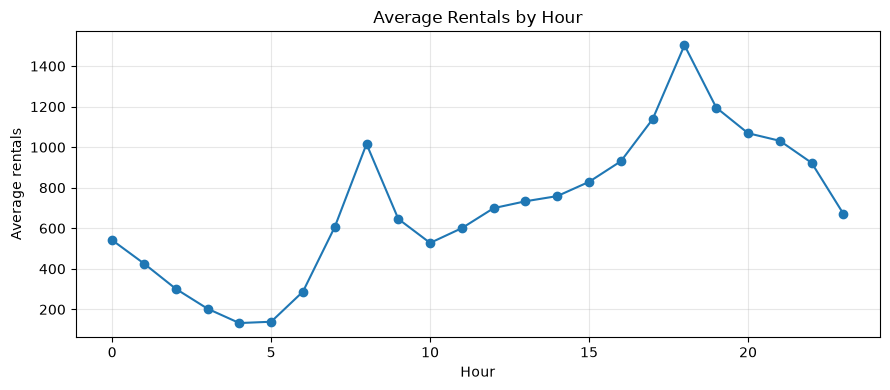

In [3]:
hourly = df.groupby('Hour')['Rented_Bike_Count'].mean()
display(hourly.round(2).to_frame('average_rentals'))
hourly.plot(figsize=(9,4), marker='o', title='Average Rentals by Hour')
plt.xlabel('Hour'); plt.ylabel('Average rentals'); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Seasonal demand

,average_rentals
Seasons,
Summer,1034.07
Autumn,819.60
Spring,730.03
Winter,225.54


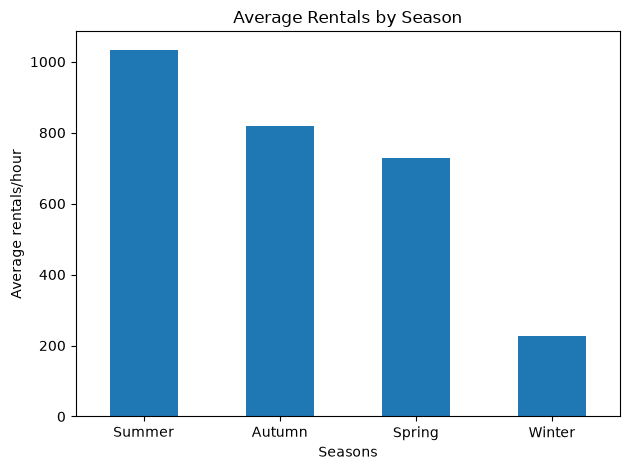

In [4]:
seasonal = df.groupby('Seasons')['Rented_Bike_Count'].mean().sort_values(ascending=False)
display(seasonal.round(2).to_frame('average_rentals'))
seasonal.plot(kind='bar', title='Average Rentals by Season')
plt.ylabel('Average rentals/hour'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## Weekday versus weekend

In [5]:
display(df.groupby('Day_Type')['Rented_Bike_Count'].agg(['mean','median','sum']).round(2))

,mean,median,sum
Day_Type,,,
Weekday,719.45,527.0,4506628
Weekend,667.34,463.0,1665686


## Temperature relationship

Rented_Bike_Count         1.000000
TemperatureC              0.538558
Hour                      0.410257
Dew_point_temperatureC    0.379788
Solar_Radiation_MJ_m2     0.261837
Visibility_10m            0.199280
Wind_speed_m_s            0.121108
Rainfallmm               -0.123074
Snowfall_cm              -0.141804
Humiditypct              -0.199780
Name: Rented_Bike_Count, dtype: float64


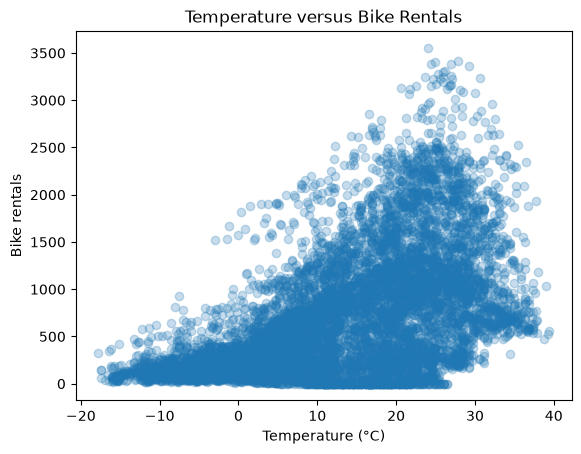

In [6]:
print(df.select_dtypes(include='number').corr(numeric_only=True)['Rented_Bike_Count'].sort_values(ascending=False))
plt.scatter(df['TemperatureC'], df['Rented_Bike_Count'], alpha=.25)
plt.xlabel('Temperature (°C)'); plt.ylabel('Bike rentals')
plt.title('Temperature versus Bike Rentals'); plt.show()

## Conclusions
- The dataset contains 8,760 hourly records.
- Total rentals are 6,172,314.
- Average hourly demand peaks at 18:00.
- Summer has the highest seasonal average; winter has the lowest.
- Correlation shows association, not causation.
- Potential outliers should be investigated rather than automatically removed.